In [1]:
using QuantumOptics, Plots

# Quantum trajectory method/Monte Carlo Wafe Function

# James Cummings with dampening

In [2]:
nc = 12; # fock cutoff
Κ = 0.5; # decay rate of cavity mode
δ = 0; # detuning (soweit noch irrelevant)

te = 5/Κ;

Basis_fock = FockBasis(nc);
a = destroy(Basis_fock);
a⁺ = dagger(a);

# time evolution

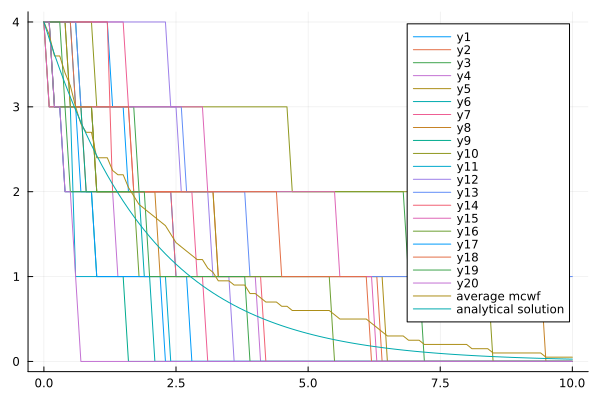

In [3]:
T = 0:0.1:te;
δ = 5;

H = -δ*a⁺*a;
ψ0 = fockstate(Basis_fock, 4);
ntr = 20;

J = [√Κ*a]; # Sprungoperator
nq = zeros(size(T)); # Vector mit einträgen 0 und länge T

for i = 1:ntr
    t, ψ0t = timeevolution.mcwf(T, ψ0, H, J);
    nq += real.(expect(a⁺*a, ψ0t)); #expectationvalue of cavity Photon number 
    plot!(t, real.(expect(a⁺*a, ψ0t)))
    end

plot!(T, nq/ntr, label="average mcwf"); plot!(T, 4*exp.(-Κ*T), label="analytical solution") # mittelwert der mcwf (links) analytische lsg zum Vergleich (rechts)


# spontaneous emission (task 2)

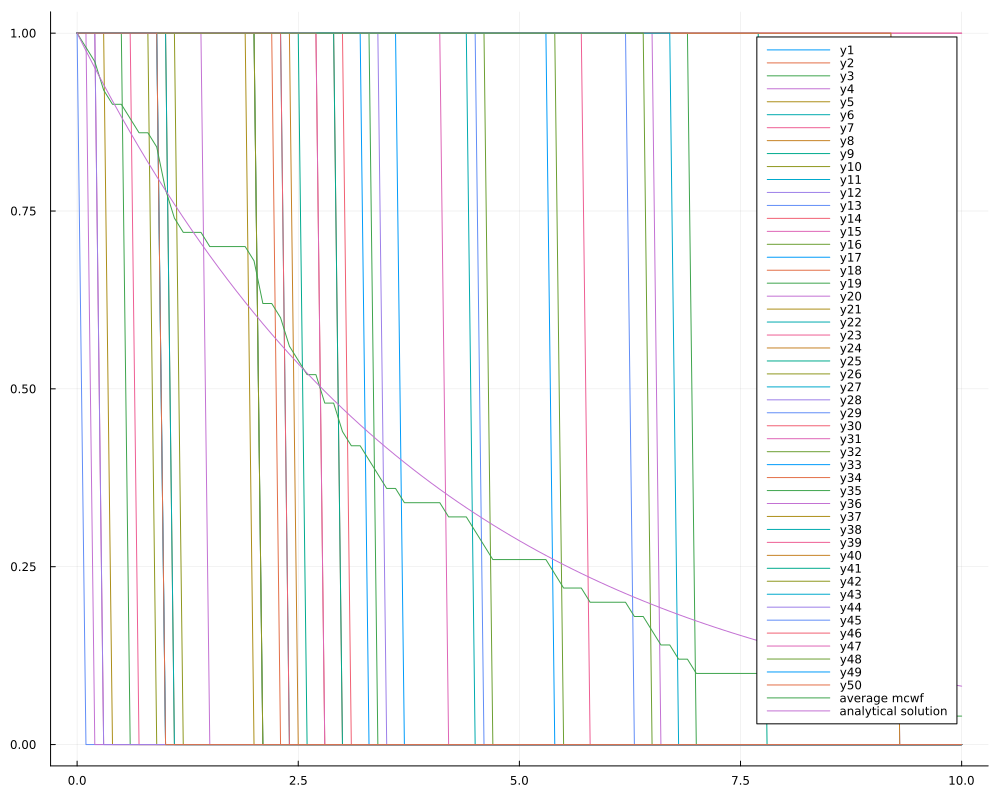

In [6]:
#man könnte auch spin 1/2 system benutzen, lässt sich aber nicht so leicht auf mehr niveaus erweitern
Basis_atom = NLevelBasis(2);
σ = transition(Basis_atom, 1,2); # übergang von 2 zu 1
σ⁺ = dagger(σ);
Ha = -δ*σ⁺*σ;
γ = 0.5*Κ
ntr = 50;
J = [√γ*σ]

ψ0a = basisstate(Basis_atom, 2)

pop2q = zeros(size(T)); # pop2q steht für population of state 2 bar
plt = plot(title="");
for j = 1:ntr
    t, ψ0at = timeevolution.mcwf(T, ψ0a, Ha, J);
    pop2q += real.(expect(dagger(σ)*σ, ψ0at));
    plt = plot!(t, real.(expect(dagger(σ)*σ, ψ0at)));
end

plt = plot!(T, pop2q/ntr, label="average mcwf"); plt = plot!(T, exp.(-γ*T), label="analytical solution");

plot(plt, size=(1000,800))


# study of JC modell with mcwf methode (task 3)

In [7]:
ħ = 1;
nf = 15;
ωa = 1;
g = 1;
δ = 0.1;

K = 0.1;
γ = 0.5;

In [8]:
basis_fock = FockBasis(nf);
basis_atom = NLevelBasis(2);

basis_jc = basis_fock ⊗ basis_atom;

#operators for atom
σ⁻ = one(basis_fock) ⊗ transition(basis_atom, 1, 2);
σ⁺ = dagger(σ⁻);

#operators for field
a = destroy(basis_fock) ⊗ one(basis_atom);
a⁺ = dagger(a);
N = a⁺*a;

J = [sqrt(2*K)*a, sqrt(γ)*σ⁻];

In [9]:
#Hamiltonian for James Cummings Modell
Ha = ħ*(ωa+δ)*σ⁺*σ⁻;
Hf = ħ*ωa*(N + 1/2*one(basis_jc));
Hw = ħ*g*(a⁺*σ⁻ + a*σ⁺);

H = Ha + Hf + Hw;

In [10]:
#initial state + timeevolution
T = 0:0.1:3
ψj_0 = basisstate(basis_fock, 1) ⊗ basisstate(basis_atom, 2); t_0, ψjt_0 = timeevolution.mcwf(T, ψj_0, H, J);
ψj_1 = basisstate(basis_fock, 2) ⊗ basisstate(basis_atom, 2); t_1, ψjt_1 = timeevolution.mcwf(T, ψj_1, H, J);
ψj_2 = basisstate(basis_fock, 3) ⊗ basisstate(basis_atom, 2); t_2, ψjt_2 = timeevolution.mcwf(T, ψj_2, H, J);
ψj_3 = basisstate(basis_fock, 4) ⊗ basisstate(basis_atom, 2); t_3, ψjt_3 = timeevolution.mcwf(T, ψj_3, H, J);

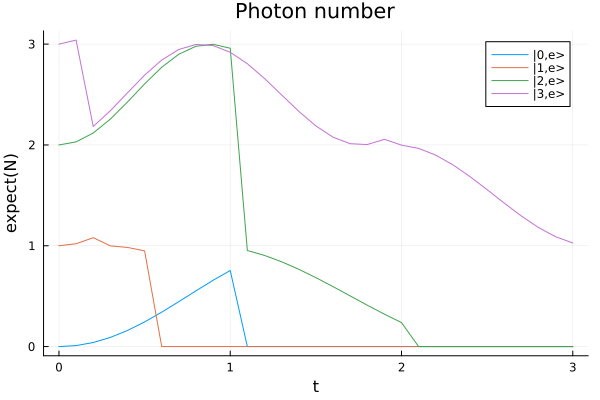

In [50]:
#Plot of Photon number

pl_n_ph = plot(xlabel="t", ylabel="expect(N)", title="Photon number");

pl_n_ph = plot!(t_0, real.(expect(N, ψjt_0)), label="|0,e>");
pl_n_ph = plot!(t_1, real.(expect(N, ψjt_1)), label="|1,e>");
pl_n_ph = plot!(t_2, real.(expect(N, ψjt_2)), label="|2,e>");
pl_n_ph = plot!(t_3, real.(expect(N, ψjt_3)), label="|3,e>")

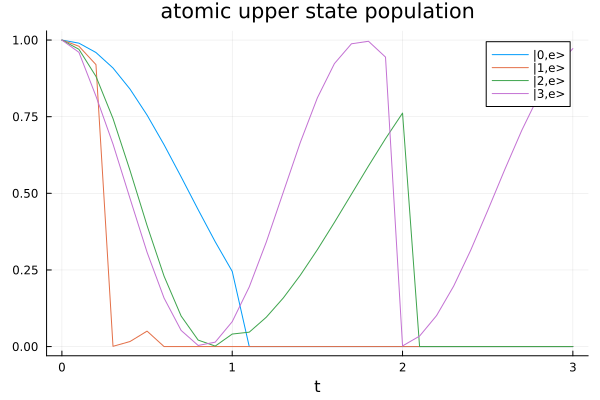

In [51]:
# Plot upper state population
pl_pop = plot(xlabel="t", ylabel="", title="atomic upper state population");

pl_pop = plot!(t_0, real.(expect(σ⁺*σ⁻, ψjt_0)), label="|0,e>");
pl_pop = plot!(t_1, real.(expect(σ⁺*σ⁻, ψjt_1)), label="|1,e>");
pl_pop = plot!(t_2, real.(expect(σ⁺*σ⁻, ψjt_2)), label="|2,e>");
pl_pop = plot!(t_3, real.(expect(σ⁺*σ⁻, ψjt_3)), label="|3,e>")

# study of coherent initial cavity state (task 4)

In [13]:
#coherent initial state
ψα_0 = coherentstate(basis_fock, 0) ⊗ basisstate(basis_atom, 2); ta_0, ψαt_0 = timeevolution.mcwf(T, ψα_0, H, J);
ψα_1 = coherentstate(basis_fock, 1) ⊗ basisstate(basis_atom, 2); ta_1, ψαt_1 = timeevolution.mcwf(T, ψα_1, H, J);
ψα_2 = coherentstate(basis_fock, 2) ⊗ basisstate(basis_atom, 2); ta_2, ψαt_2 = timeevolution.mcwf(T, ψα_2, H, J);
ψα_3 = coherentstate(basis_fock, 3) ⊗ basisstate(basis_atom, 2); ta_3, ψαt_3 = timeevolution.mcwf(T, ψα_3, H, J);

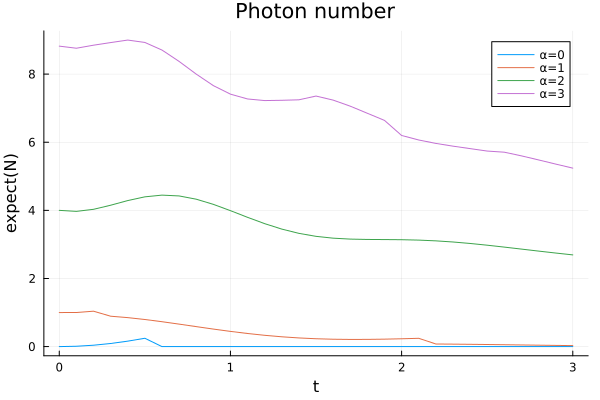

In [52]:
pl_n_pha = plot(xlabel="t", ylabel="expect(N)", title="Photon number");

pl_n_pha = plot!(ta_0, real.(expect(N, ψαt_0)), label="α=0");
pl_n_pha = plot!(ta_1, real.(expect(N, ψαt_1)), label="α=1");
pl_n_pha = plot!(ta_2, real.(expect(N, ψαt_2)), label="α=2");
pl_n_pha = plot!(ta_3, real.(expect(N, ψαt_3)), label="α=3")

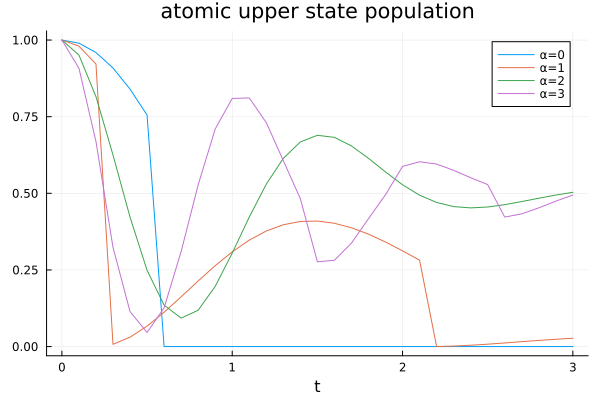

In [53]:
pl_popa = plot(xlabel="t", ylabel="", title="atomic upper state population");

pl_popa = plot!(ta_0, real.(expect(σ⁺*σ⁻, ψαt_0)), label="α=0");
pl_popa = plot!(ta_1, real.(expect(σ⁺*σ⁻, ψαt_1)), label="α=1");
pl_popa = plot!(ta_2, real.(expect(σ⁺*σ⁻, ψαt_2)), label="α=2");
pl_popa = plot!(ta_3, real.(expect(σ⁺*σ⁻, ψαt_3)), label="α=3")

# average over many trajectories for coherent state

In [58]:
γ = 0.05; K = 0.01;
J = [sqrt(2*K)*a, sqrt(γ)*σ⁻];
T = 0:0.01:100
n_tra = 500;
n_avg = zeros(size(T));
pop_avg = zeros(size(T));


ψα2 = coherentstate(basis_fock, 1) ⊗ basisstate(basis_atom, 2);

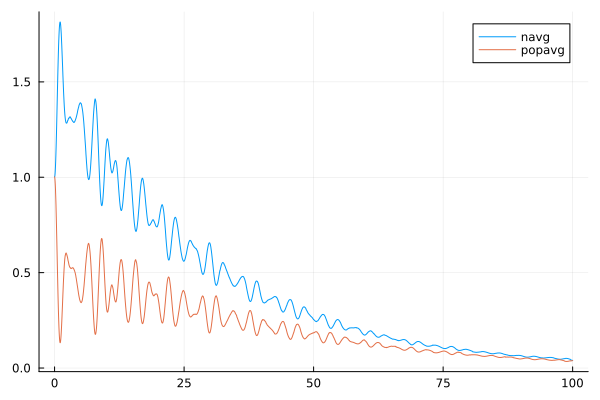

In [59]:
for i in 0:n_tra
    tout, ψα2t = timeevolution.mcwf(T, ψα2, H, J);

    n_avg += real.(expect(N, ψα2t));
    pop_avg += real.(expect(σ⁺*σ⁻, ψα2t));
end

pl_navg = plot(xlabel="", ylabel="", title="");
pl_popavg = plot(xlabel="", ylabel="", title="");

pl_navg = plot!(T, n_avg/n_tra, label = "navg");
pl_popavg = plot!(T, pop_avg/n_tra, label = "popavg")